# Лабораторная работа 6 / 实验六答辩
Загрузить сохранённые веса и распознать изображение без обучения.

通过 run.ps1 -Mode Notebook 启动，按顺序执行。训练不在本笔记本中运行。

In [1]:
from pathlib import Path
import json, time, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from mnist_lab.model import Network
from mnist_lab.data import ROOT
from mnist_lab.inference import show_prediction
start = time.perf_counter()
model = Network.load(ROOT / 'output' / 'best_model.npz')
print('Python:', sys.executable)
print('Weight loading seconds:', round(time.perf_counter()-start, 4))
summary = json.loads((ROOT / 'output' / 'summary.json').read_text(encoding='utf-8'))
print('Best model:', summary['winner'], 'Test accuracy:', summary['test_accuracy'])

Python: D:\Study-Note\AISystem\Labs\lab6\.venv\Scripts\python.exe
Weight loading seconds: 0.0176
Best model: D Test accuracy: 0.9824


## Результаты обучения / 训练结果
Выбор модели выполнен только по val. / 只按验证集选模型。

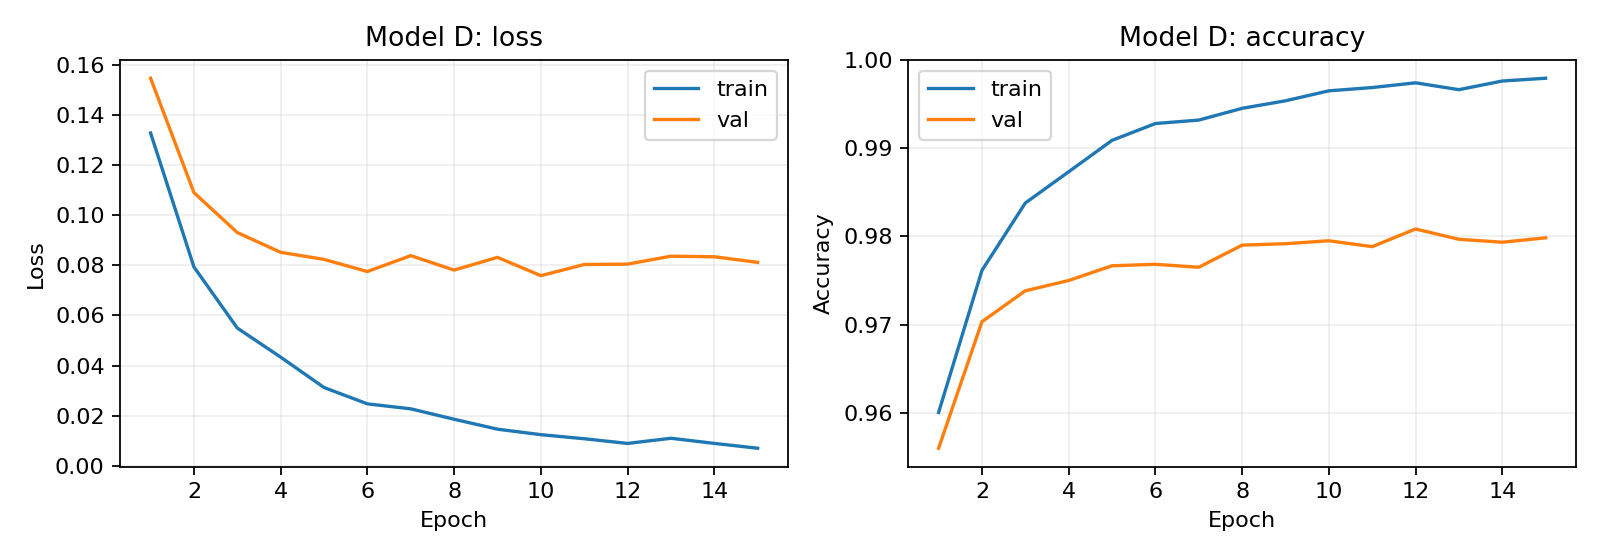

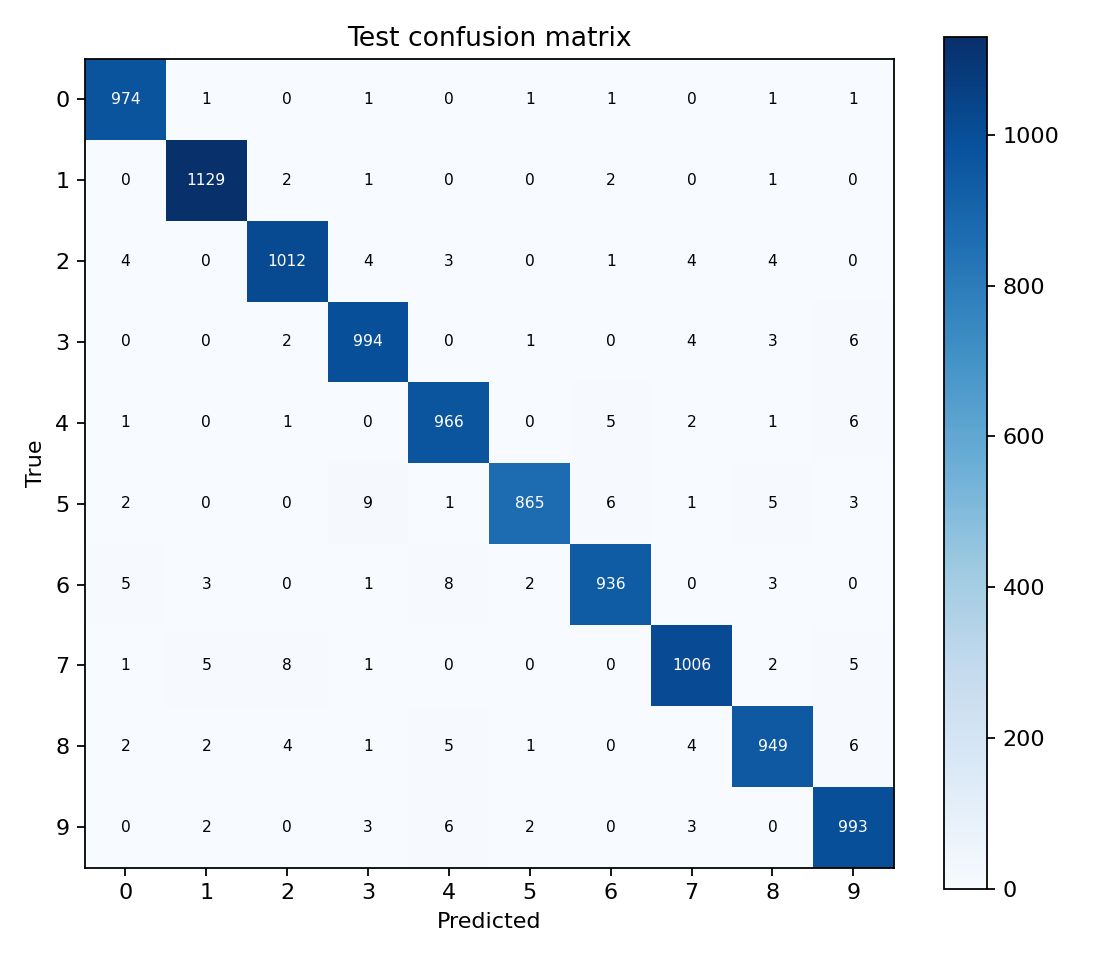

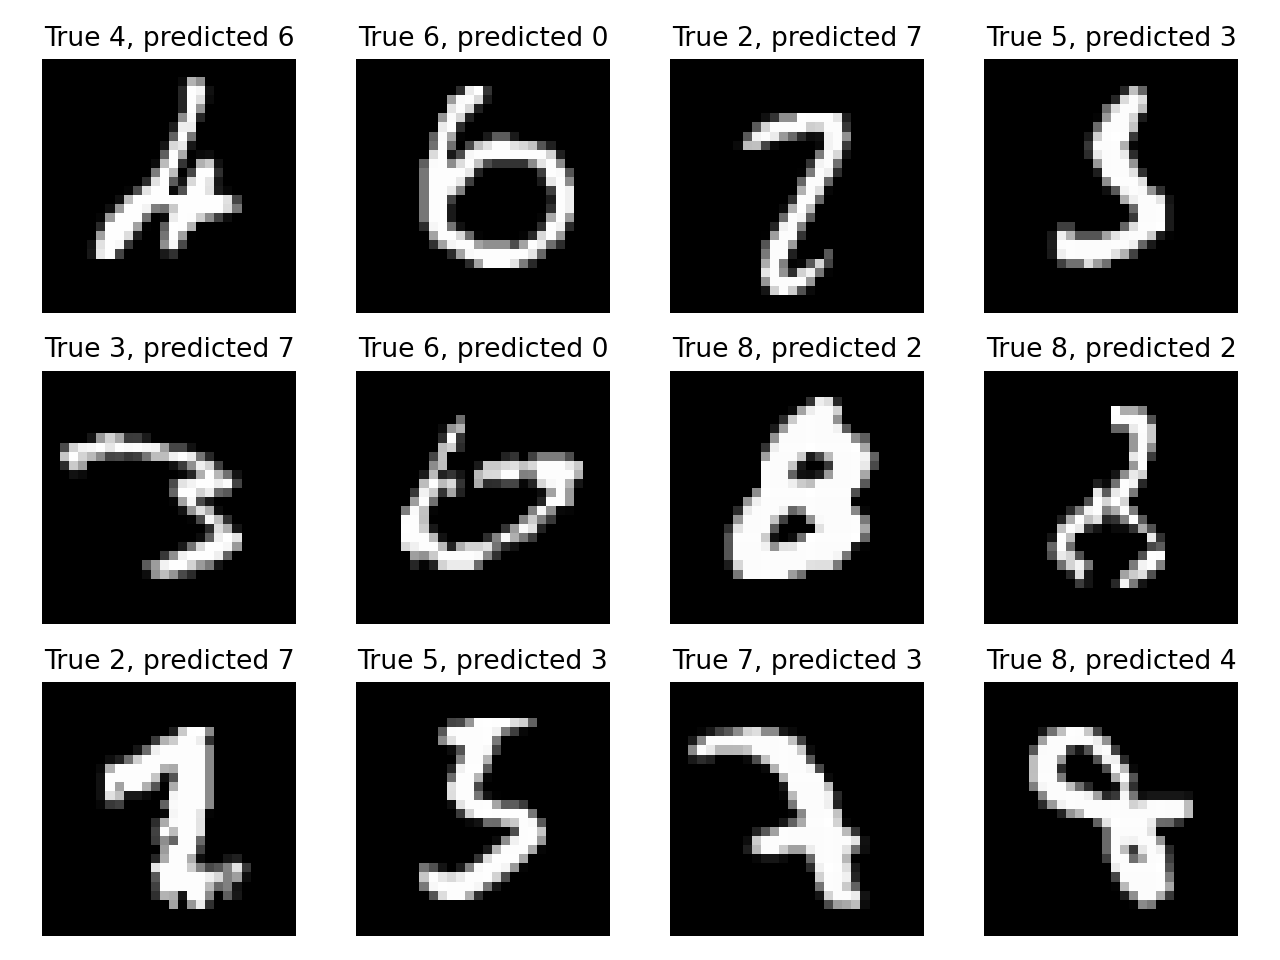

In [2]:
from IPython.display import Image as DisplayImage
for name in ['curves_' + summary['winner'] + '.png', 'confusion.png', 'errors.png']:
    display(DisplayImage(filename=str(ROOT / 'output' / 'figures' / name)))

## Проверка интерфейса / 接口检查
Следующая ячейка использует тестовое изображение MNIST только как проверку запуска. Это не собственный рисунок и не новая оценка качества.
下一格用一个 MNIST 测试对象检查运行流程，不冒充本人手绘图，也不重新选择模型。

Prediction: 7; inference: 0.0013 s
{0: 5.773356792637685e-11, 1: 6.8851302437167305e-09, 2: 1.732012293587104e-07, 3: 1.5254664731401135e-07, 4: 4.957753500269002e-13, 5: 8.594892159097256e-12, 6: 5.245589119323713e-13, 7: 0.9999996423721313, 8: 1.4232312377238099e-11, 9: 1.0965841568122414e-09}


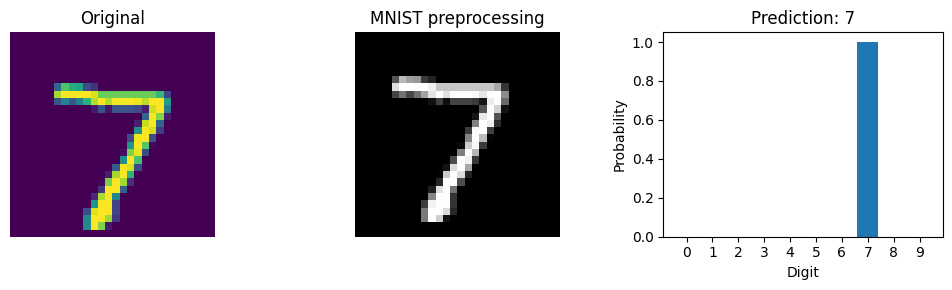

In [3]:
from mnist_lab.data import read_idx
from PIL import Image
preview = ROOT / '_qa' / 'mnist_interface_check.png'
preview.parent.mkdir(exist_ok=True)
Image.fromarray(read_idx(ROOT / 'data' / 't10k-images-idx3-ubyte.gz')[0]).save(preview)
fig, digit, probabilities = show_prediction(model, preview)
display(fig)
plt.close(fig)
assert probabilities.shape == (10,) and np.isclose(probabilities.sum(), 1)

## Собственный рисунок / 本人手绘数字
В Paint нарисовать одну цифру на белом фоне и сохранить PNG в drawings. Например: 2.png, 7.png, 9.png. Изменить путь ниже. Показывать исходное изображение преподавателю. На защите до трёх попыток; хотя бы одна должна быть верной.
在 Paint 绘制一张一位数字图，保存到 drawings，修改下面路径后运行。每次展示原图和处理图。

Prediction: 2; inference: 0.0262 s


{0: 0.005419935565441847, 1: 0.16379214823246002, 2: 0.7805395126342773, 3: 0.008204719051718712, 4: 0.002026977250352502, 5: 0.008136372081935406, 6: 0.01654054783284664, 7: 0.004576853010803461, 8: 0.010012198239564896, 9: 0.0007506789406761527}


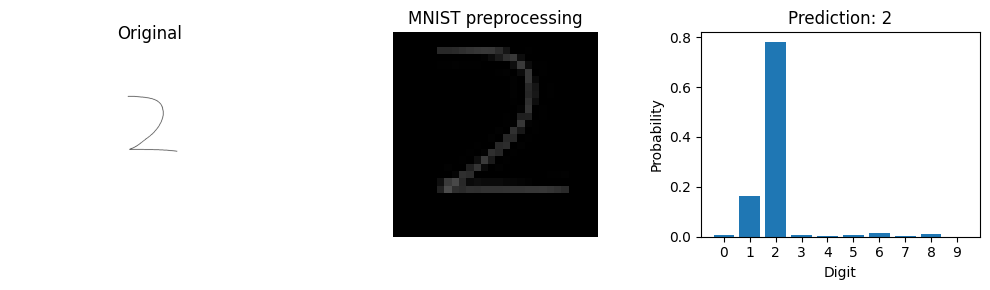

In [4]:
image_path = ROOT / 'drawings' / '2.png'  # Change to the teacher's image
if image_path.exists():
    fig, digit, probabilities = show_prediction(model, image_path)
    display(fig)
    plt.close(fig)
else:
    print('Add your own drawing and change image_path. / 请先保存本人手绘图片。')

## Собственные рисунки 2 6 7 / 本人手绘实测
Три оригинальных рисунка из Paint. Веса и предобработка не изменялись. Результаты 2→2, 6→5, 7→7: два верных ответа из трёх. Ошибка сохранена.
使用原有权重与预处理，保留真实误判。

File: 2.png True digit: 2


Prediction: 2; inference: 0.0347 s
{0: 0.005419935565441847, 1: 0.16379214823246002, 2: 0.7805395126342773, 3: 0.008204719051718712, 4: 0.002026977250352502, 5: 0.008136372081935406, 6: 0.01654054783284664, 7: 0.004576853010803461, 8: 0.010012198239564896, 9: 0.0007506789406761527}


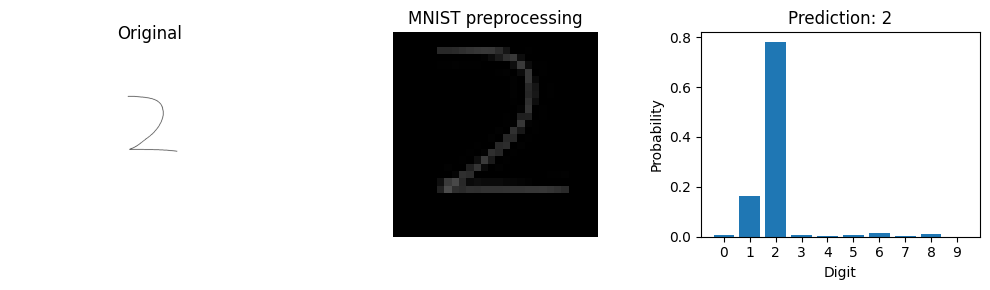

Correct: True
File: 6.png True digit: 6


Prediction: 5; inference: 0.0297 s
{0: 0.04078903794288635, 1: 0.06718997657299042, 2: 0.017313405871391296, 3: 0.021780142560601234, 4: 0.055664900690317154, 5: 0.31578370928764343, 6: 0.2755883038043976, 7: 0.03963068872690201, 8: 0.1378011554479599, 9: 0.02845866046845913}


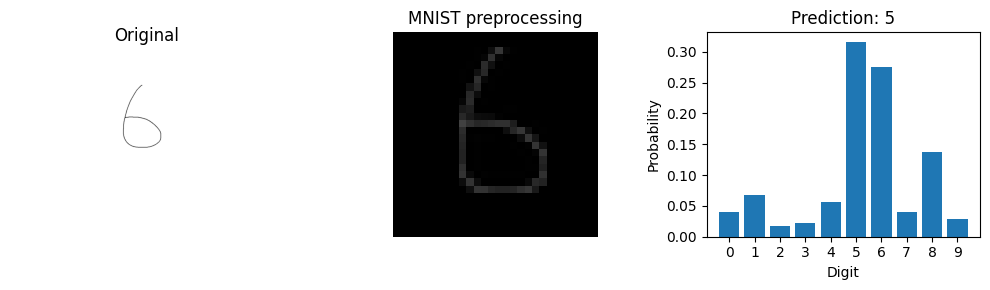

Correct: False
File: 7.png True digit: 7


Prediction: 7; inference: 0.0275 s
{0: 0.050048086792230606, 1: 0.07650833576917648, 2: 0.07117220759391785, 3: 0.07792440056800842, 4: 0.03943876177072525, 5: 0.07555318623781204, 6: 0.022789524868130684, 7: 0.45661690831184387, 8: 0.048073675483465195, 9: 0.08187488466501236}


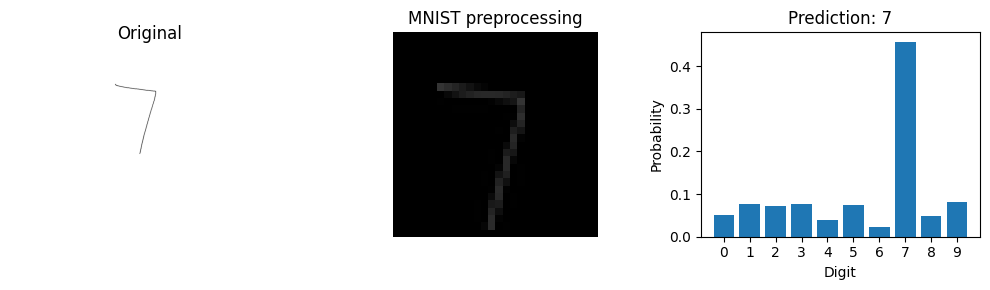

Correct: True


In [5]:
for name, true_digit in [('2.png', 2), ('6.png', 6), ('7.png', 7)]:
    print('File:', name, 'True digit:', true_digit)
    fig, digit, probabilities = show_prediction(model, ROOT / 'drawings' / name)
    display(fig)
    plt.close(fig)
    print('Correct:', digit == true_digit)